# Hand Gesture Digit Detection dengan YOLOv8

Notebook ini menggunakan **YOLOv8** untuk mendeteksi angka (0–9) dari gesture tangan secara real-time melalui kamera.

> **Perhatian:** Gunakan virtual environment (VENV) sebelum menjalankan notebook ini.

## 1. Instalasi Dependencies

In [ ]:
# Jalankan cell ini sekali saja
# PyTorch CUDA 12.4 harus diinstall manual lewat terminal (bukan pip biasa):
# pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124
# download dataset at https://app.roboflow.com/ardhianthony-reza-pramono/hand-gesture-gizg2-w0cuw/train 
%pip install ultralytics opencv-python numpy ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## code starts from here
### 2. Import Library

In [2]:
import cv2
import numpy as np
import threading
import time
import os
import torch
from ultralytics import YOLO
from IPython.display import display, Image
import ipywidgets as widgets

print(f'torch          : {torch.__version__}')
print(f'CUDA available : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU            : {torch.cuda.get_device_name(0)}')
    print(f'VRAM           : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')
else:
    print('GPU tidak terdeteksi — training akan berjalan di CPU (lambat)')
    print('Install PyTorch CUDA: pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124')

print('\nLibrary berhasil diimport!')

torch          : 2.6.0+cu124
CUDA available : True
GPU            : NVIDIA GeForce RTX 3050 Laptop GPU
VRAM           : 4.0 GB

Library berhasil diimport!


## 3. Konfigurasi

- **`MODEL_PATH`** — setelah training selesai, otomatis diisi path best model
- **`DATASET_YAML`** — path ke `data.yaml` dataset gesture tangan
- **`CONF_THRESHOLD`** — confidence minimum deteksi (0.0–1.0)
- **`CAMERA_INDEX`** — index kamera (0 = default)

In [3]:
# ============================================================
# KONFIGURASI
# ============================================================

# Path dataset gesture tangan
DATASET_YAML = r'Hand Gesture.v1i.yolov8/data.yaml'

# Setelah training selesai, MODEL_PATH diupdate otomatis ke best.pt
# Sebelum training: pakai yolov8n.pt sebagai base
MODEL_PATH = 'runs/train/hand_gesture/weights/best.pt'
if not os.path.exists(MODEL_PATH):
    MODEL_PATH = 'yolov8n.pt'  # fallback ke pretrained jika belum ditraining

# Label kelas sesuai dataset (6 kelas: angka 0-5)
GESTURE_LABELS = {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5'}

CONF_THRESHOLD = 0.5   # confidence threshold
CAMERA_INDEX   = 0     # index kamera (0 = default)

# Deteksi device — GPU jika tersedia, CPU sebagai fallback
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

print(f'Dataset YAML : {DATASET_YAML}')
print(f'Model        : {MODEL_PATH}')
print(f'Confidence   : {CONF_THRESHOLD}')
print(f'Kamera       : {CAMERA_INDEX}')
print(f'Device       : {"GPU (" + torch.cuda.get_device_name(0) + ")" if torch.cuda.is_available() else "CPU"}')

Dataset YAML : Hand Gesture.v1i.yolov8/data.yaml
Model        : yolov8n.pt
Confidence   : 0.5
Kamera       : 0
Device       : GPU (NVIDIA GeForce RTX 3050 Laptop GPU)


## 4. Load Model YOLOv8

In [4]:
model = YOLO(MODEL_PATH)

print(f'Model berhasil dimuat : {MODEL_PATH}')
print(f'Jumlah kelas          : {len(model.names)}')
print(f'Nama kelas            : {model.names}')

Model berhasil dimuat : yolov8n.pt
Jumlah kelas          : 80
Nama kelas            : {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 

## 5. Fungsi Helper

In [5]:
def draw_detections(frame, results, use_gesture_labels=False):
    """
    Gambar bounding box dan label hasil deteksi pada frame.
    Mengembalikan frame yang sudah dianotasi dan list deteksi.
    """
    annotated = frame.copy()
    detections = []

    for result in results:
        boxes = result.boxes
        if boxes is None:
            continue

        for box in boxes:
            conf = float(box.conf[0])
            if conf < CONF_THRESHOLD:
                continue

            cls_id = int(box.cls[0])
            x1, y1, x2, y2 = map(int, box.xyxy[0])

            if use_gesture_labels:
                label_name = GESTURE_LABELS.get(cls_id, f'Class {cls_id}')
            else:
                label_name = model.names.get(cls_id, f'Class {cls_id}')

            label_text = f'{label_name}: {conf:.2f}'

            # Warna unik per kelas
            color = (
                (cls_id * 37 + 80)  % 255,
                (cls_id * 97 + 150) % 255,
                (cls_id * 61 + 200) % 255,
            )

            cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 2)

            (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2)
            cv2.rectangle(annotated, (x1, y1 - th - 10), (x1 + tw + 4, y1), color, -1)
            cv2.putText(
                annotated, label_text, (x1 + 2, y1 - 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA
            )

            detections.append({
                'class_id': cls_id, 'label': label_name,
                'confidence': conf,  'bbox': (x1, y1, x2, y2),
            })

    return annotated, detections


def frame_to_jpeg(frame):
    """Konversi frame BGR numpy ke bytes JPEG."""
    _, buf = cv2.imencode('.jpg', frame, [cv2.IMWRITE_JPEG_QUALITY, 85])
    return bytes(buf)


print('Fungsi helper siap.')

Fungsi helper siap.


## 6. Snapshot — Test Satu Frame

Ambil satu frame dari kamera dan jalankan deteksi. Berguna untuk memastikan setup benar sebelum menjalankan real-time.

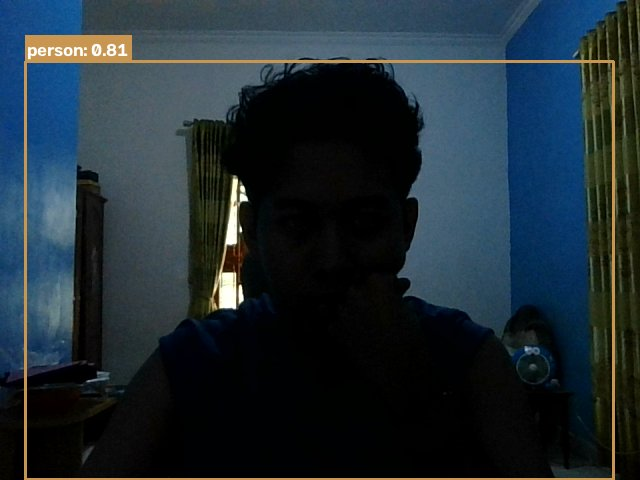


Deteksi (1):
  [0] person  conf=0.81  bbox=(25, 61, 613, 479)


In [6]:
cap = cv2.VideoCapture(CAMERA_INDEX)

if not cap.isOpened():
    print(f'ERROR: Tidak dapat membuka kamera index {CAMERA_INDEX}')
else:
    ret, frame = cap.read()
    cap.release()

    if not ret:
        print('ERROR: Gagal membaca frame dari kamera.')
    else:
        results = model.predict(frame, conf=CONF_THRESHOLD, verbose=False)
        annotated, detections = draw_detections(frame, results)

        display(Image(data=frame_to_jpeg(annotated)))

        if detections:
            print(f'\nDeteksi ({len(detections)}):')
            for d in detections:
                print(f"  [{d['class_id']}] {d['label']}  conf={d['confidence']:.2f}  bbox={d['bbox']}")
        else:
            print('\nTidak ada objek terdeteksi. Coba turunkan CONF_THRESHOLD.')

## 7. Deteksi Real-Time dari Kamera

Stream kamera langsung di notebook menggunakan `ipywidgets`.

**Cara menghentikan:** Klik tombol **Stop Kamera** atau interrupt kernel (`Kernel → Interrupt`).

In [11]:
img_widget  = widgets.Image(format='jpeg', width=640, height=480)
info_widget = widgets.Label(value='Memulai kamera...')
stop_btn    = widgets.Button(description='Stop Kamera', button_style='danger')

display(widgets.VBox([img_widget, info_widget, stop_btn]))

running = {'value': True}

def on_stop(b):
    running['value'] = False
    info_widget.value = 'Kamera dihentikan.'

stop_btn.on_click(on_stop)


def camera_loop():
    cap = cv2.VideoCapture(CAMERA_INDEX)
    if not cap.isOpened():
        info_widget.value = f'ERROR: Tidak dapat membuka kamera index {CAMERA_INDEX}'
        return

    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

    fps_time    = time.time()
    frame_count = 0

    try:
        while running['value']:
            ret, frame = cap.read()
            if not ret:
                info_widget.value = 'ERROR: Gagal membaca frame.'
                break

            frame   = cv2.flip(frame, 1)  # mirror horizontal
            results = model.predict(frame, conf=CONF_THRESHOLD, verbose=False)
            annotated, detections = draw_detections(frame, results)

            # Hitung dan tampilkan FPS
            frame_count += 1
            elapsed = time.time() - fps_time
            fps = frame_count / max(elapsed, 1e-6)
            if elapsed >= 1.0:
                fps_time    = time.time()
                frame_count = 0

            cv2.putText(
                annotated, f'FPS: {fps:.1f}',
                (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                (0, 255, 0), 2, cv2.LINE_AA
            )

            img_widget.value = frame_to_jpeg(annotated)

            if detections:
                labels = ', '.join(
                    f"{d['label']} ({d['confidence']:.2f})" for d in detections
                )
                info_widget.value = f'Terdeteksi: {labels}'
            else:
                info_widget.value = 'Menunggu gesture tangan...'
    finally:
        cap.release()


t = threading.Thread(target=camera_loop, daemon=True)
t.start()

## 8. Training Custom Model — Hand Gesture (0–5)

Dataset sudah tersedia di folder `Hand Gesture.v1i.yolov8/` dengan **6 kelas** (angka 0–5).

Training menggunakan `yolov8n.pt` sebagai pretrained weights dan akan disimpan ke `runs/train/hand_gesture/`.

> **Estimasi waktu:** ~10–30 menit (tergantung GPU/CPU dan jumlah epoch).

In [8]:
# ============================================================
# TRAINING — Hand Gesture Digit Detection (kelas 0–5)
# ============================================================

import os

print(f'Training device: {"GPU - " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')

# Path output absolut — hindari path nested yang salah
TRAIN_PROJECT = os.path.abspath('runs')
TRAIN_NAME    = 'hand_gesture'

# Mulai dari pretrained YOLOv8n (nano — cepat, ringan)
train_model = YOLO('yolov8n.pt')

train_results = train_model.train(
    data=os.path.abspath(DATASET_YAML),  # path absolut ke data.yaml
    epochs=50,           # jumlah epoch training
    imgsz=640,           # ukuran input gambar
    batch=8,             # batch=8 aman untuk VRAM 4GB
    name=TRAIN_NAME,
    project=TRAIN_PROJECT,
    patience=10,         # early stopping jika tidak improve 10 epoch
    device=DEVICE,       # GPU (0) atau CPU
    workers=0,           # workers=0 di Windows notebook untuk hindari deadlock
    exist_ok=True,
    val=True,
    cache=False,
)

# Path ke model terbaik hasil training
BEST_MODEL_PATH = os.path.join(TRAIN_PROJECT, TRAIN_NAME, 'weights', 'best.pt')
print(f'\nTraining selesai!')
print(f'Best model tersimpan di: {BEST_MODEL_PATH}')

Training device: GPU - NVIDIA GeForce RTX 3050 Laptop GPU
Ultralytics 8.4.203  Python-3.13.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\ibm_bob_test\Hand Gesture.v1i.yolov8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.

## 9. Evaluasi Model Hasil Training

In [9]:
# Load model hasil training dan evaluasi pada data validasi
best_model = YOLO(BEST_MODEL_PATH)

val_results = best_model.val(
    data=DATASET_YAML,
    imgsz=640,
    split='val',
)

print(f'mAP50     : {val_results.box.map50:.4f}')
print(f'mAP50-95  : {val_results.box.map:.4f}')
print(f'Precision : {val_results.box.mp:.4f}')
print(f'Recall    : {val_results.box.mr:.4f}')

Ultralytics 8.4.203  Python-3.13.0 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,133,922 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 510.4±797.4 MB/s, size: 245.0 KB)
val: Scanning D:\ibm_bob_test\Hand Gesture.v1i.yolov8\valid\labels.cache... 1077 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1077/1077 376.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 1.9it/s 35.9s0.2ss5
                   all       1077       1081       0.86      0.817      0.893      0.737
                     0         18         21       0.59      0.905      0.729      0.487
                     1        227        228      0.982      0.729      0.959      0.755
                     2        216        216      0.968      0.836      0.941      0.789
                     3        252        252      0.995      0.796      0.964     

## 10. Load Model Terbaik untuk Deteksi Real-Time

Setelah training selesai, ganti model yang digunakan untuk deteksi kamera dengan model terbaik hasil training.

In [10]:
# Load model hasil training ke variabel 'model' yang dipakai Cell 6 & 7
model = YOLO(BEST_MODEL_PATH)
MODEL_PATH = BEST_MODEL_PATH

# Update gesture labels sesuai dataset (6 kelas: 0-5)
GESTURE_LABELS = {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5'}

print(f'Model dimuat: {MODEL_PATH}')
print(f'Kelas       : {model.names}')
print('\nSiap untuk deteksi real-time! Jalankan Cell 6 atau Cell 7.')

Model dimuat: d:\ibm_bob_test\runs\hand_gesture\weights\best.pt
Kelas       : {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5'}

Siap untuk deteksi real-time! Jalankan Cell 6 atau Cell 7.


---
## Ringkasan Alur

```
Dataset (train+valid) → YOLOv8.train() → best.pt → load model → Kamera → Deteksi
```

| Cell | Fungsi |
|------|--------|
| 1    | Install: ultralytics, opencv-python, numpy, ipywidgets |
| 2    | Import library |
| 3    | Konfigurasi (path dataset, model, threshold, kamera) |
| 4    | Load model (pretrained / hasil training) |
| 5    | Fungsi helper (draw_detections, frame_to_jpeg) |
| 6    | Snapshot satu frame — tes cepat |
| 7    | Real-time deteksi dari kamera |
| **8**| **Training model dari dataset Hand Gesture** |
| 9    | Evaluasi hasil training (mAP, precision, recall) |
| 10   | Load best model → siap deteksi real-time |